In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
eq = pd.read_csv("/content/drive/MyDrive/Earthquake_Project/earthquakes.tsv", sep="\t")
eq.shape

(6698, 39)

In [35]:
cleaneq = eq.dropna(subset=['Mag', 'Focal Depth (km)'])
cleaneq.shape

(3566, 39)

**STEP ONE**

**1. Numerical Features**

Year: -2150 to 2026  
Month: 1–12  
Day: 1–31  
Hour: 0–23  
Minute: 0–59  
Second: 0–59  
Latitude: -90 to 90  
Longitude: -180 to 180  
Focal Depth (km): 0–100+  
Magnitude (Mag): 0–10+  
MMI Intensity: 1–12  
Deaths: 0+  
Missing: 0+  
Injuries: 0+  
Damage (Millions): 0+  
Houses Destroyed: 0+  
Houses Damaged: 0+  
Total Deaths: 0+  
Total Missing: 0+  
Total Injuries: 0+  
Total Damage (Millions): 0+  
Total Houses Destroyed: 0+  
Total Houses Damaged: 0+  

**2. Categorical Features**

Search Parameters: Dataset search information  
Tsu: Tsunami event identifiers  
Vol: Volcano event identifiers  
Location Name: Countries, cities, and regions  

Death Description: 1, 2, 3, 4  
Missing Description: 1, 2, 3, 4  
Injuries Description: 1, 2, 3, 4  
Damage Description: 1, 2, 3, 4  
Houses Destroyed Description: 1, 2, 3, 4  
Houses Damaged Description: 1, 2, 3, 4  
Total Death Description: 1, 2, 3, 4  
Total Missing Description: 1, 2, 3, 4  
Total Injuries Description: 1, 2, 3, 4  
Total Damage Description: 1, 2, 3, 4  
Total Houses Destroyed Description: 1, 2, 3, 4  
Total Houses Damaged Description: 1, 2, 3, 4  

**3. Category Values**

Death, Missing, and Injury Descriptions:  
1 = Few (1–50)  
2 = Some (51–100)  
3 = Many (101–1,000)  
4 = Very Many (1,001+)  

Damage Description:  
1 = Limited (less than $1 million)  
2 = Moderate ($1–5 million)  
3 = Severe ($5–25 million)  
4 = Extreme (more than $25 million)  

**STEP TWO**

These histograms show the distribution of earthquake magnitudes and depths.

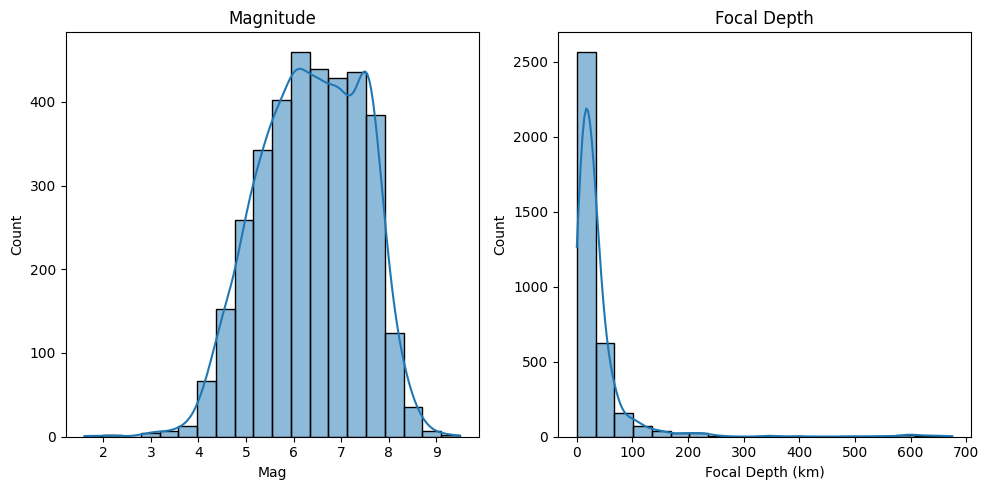

In [36]:
fig, axes = plt.subplots(1,2,figsize=(10,5))

sns.histplot(x="Mag",data=cleaneq,bins=20,kde=True,ax=axes[0])
axes[0].set_title("Magnitude")
sns.histplot(x="Focal Depth (km)",data=cleaneq,bins=20,kde=True,ax=axes[1])
axes[1].set_title("Focal Depth")

plt.tight_layout()
plt.show()

This kdeplot helps showcase the connection between magnitude and focal depth in significant earthquakes

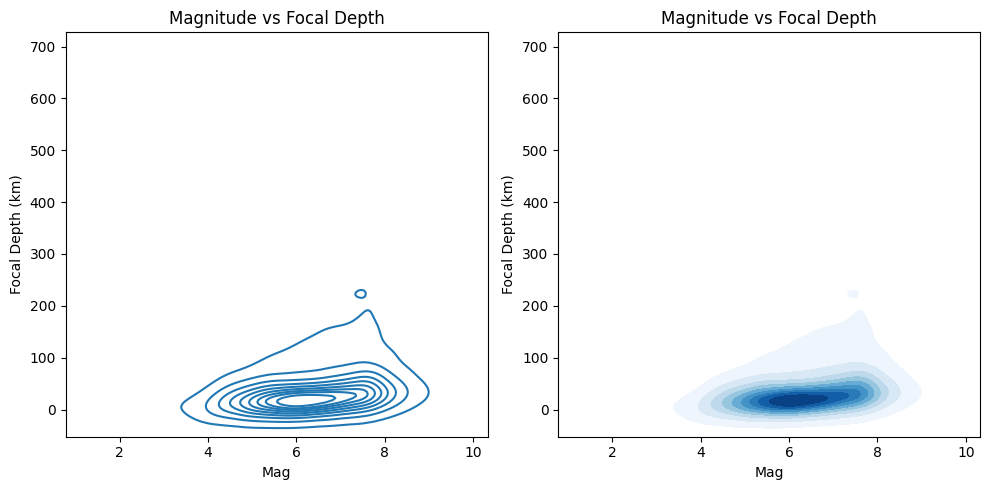

In [37]:
fig, axes= plt.subplots(1,2,figsize=(10,5))

sns.kdeplot(data=cleaneq,x="Mag",y="Focal Depth (km)",ax=axes[0])
axes[0].set_title("Magnitude vs Focal Depth")
sns.kdeplot(data=cleaneq,x="Mag",y="Focal Depth (km)",fill=True,cmap="Blues",ax=axes[1])
axes[1].set_title("Magnitude vs Focal Depth")

plt.tight_layout()
plt.show()

In [38]:
cleanyeareq = cleaneq.dropna(subset=['Year'])
cleanyeareq.shape

(3566, 39)

This countplot helps showcase the increase in the documentation in significant earthquakes across history

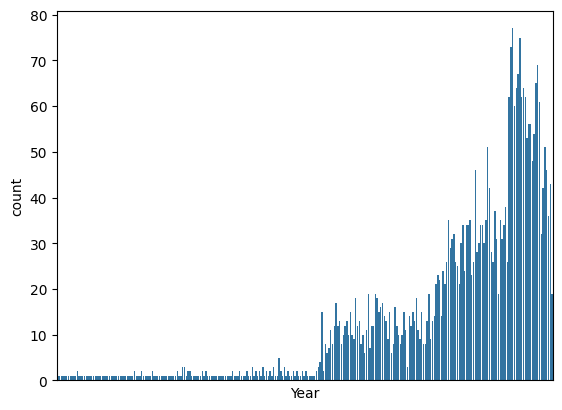

In [39]:
ax = sns.countplot(x="Year",data=cleanyeareq)
ax.tick_params(axis='x',bottom=False,labelbottom=False)
plt.show()

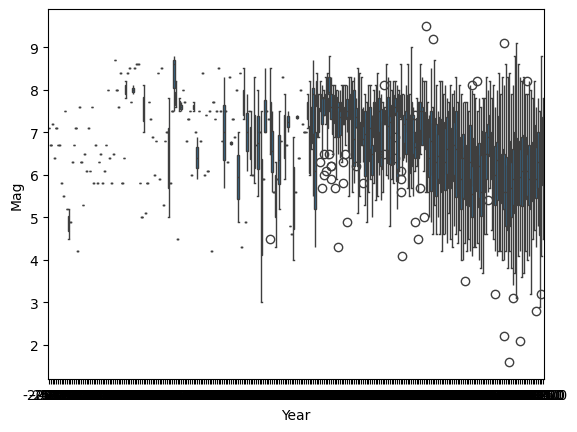

In [40]:
sns.boxplot(x="Year",y="Mag",data=cleanyeareq)
plt.show()

In [41]:
cleanvioeq = eq.dropna(subset=['MMI Int','Mag'])
cleanvioeq.shape

(2541, 39)

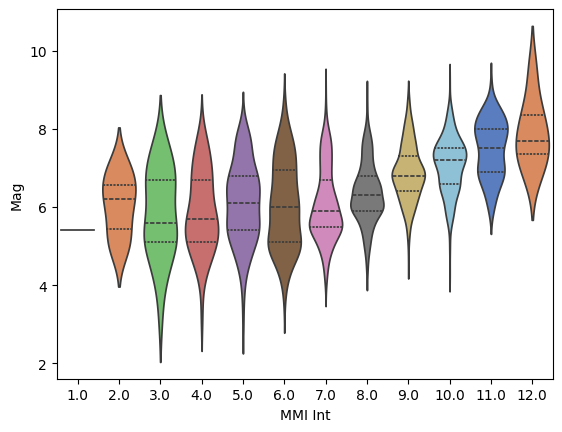

In [42]:
sns.violinplot(x="MMI Int",y="Mag",data=cleanvioeq,inner="quartile",palette="muted",hue="MMI Int",legend=False)
plt.show()

**STEP THREE**

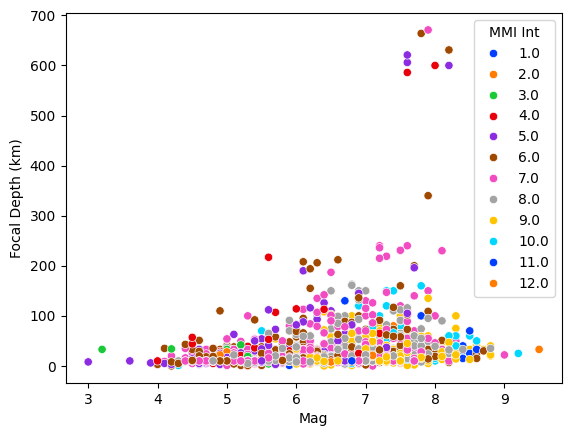

In [43]:
sns.scatterplot(x="Mag", y="Focal Depth (km)", hue="MMI Int", data=cleaneq,palette = "bright")
plt.show()

In [44]:
cleanco = eq.copy()
cleanco["Country"] = (eq["Location Name"].str.split(":").str[0].str.strip())
cleanco.shape

top5 = cleanco["Country"].value_counts().head(5).index
top5

Index(['CHINA', 'INDONESIA', 'IRAN', 'JAPAN', 'TURKEY'], dtype='object', name='Country')

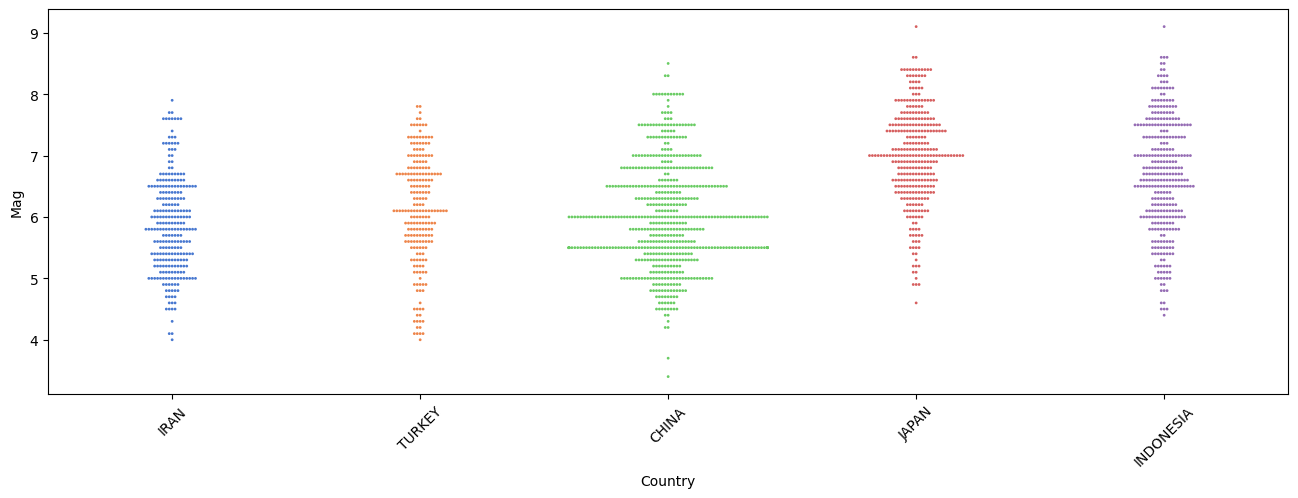

In [45]:
plt.figure(figsize=(16,5))

sns.swarmplot(x="Country",y="Mag",data=cleanco[cleanco["Country"].isin(top5)],size=2,hue = "Country", palette = "muted")
plt.xticks(rotation=45)
plt.show()

In [46]:

cleanyeareq["Century"]= (eq["Year"] // 100 * 100)
cleanyeareq.shape

(3566, 40)

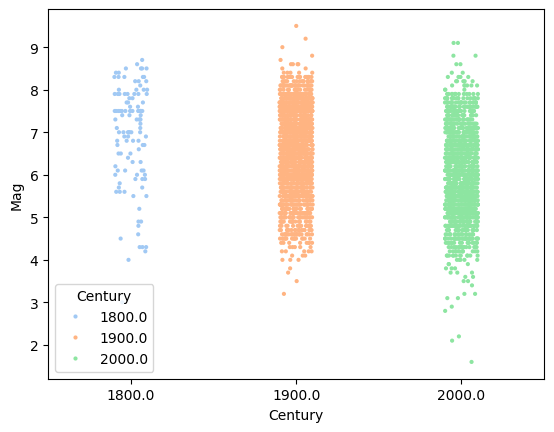

In [47]:

sns.stripplot(x="Century",y="Mag",data=cleanyeareq[cleanyeareq["Year"] >= 1800],jitter=True,size=3,hue = "Century",palette = "pastel")
plt.show()

**STEP FOUR**

This section summarizes the earthquake dataset using Pandas functions. The shape function identifies the number of rows and columns, the info function displays feature names, data types, and missing values, and the describe function provides statistical summaries of numerical and categorical features.

In [48]:
eq.shape
eq.info()
eq.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 39 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      object 
 1   Year                                6697 non-null   float64
 2   Mo                                  6293 non-null   float64
 3   Dy                                  6122 non-null   float64
 4   Hr                                  4580 non-null   float64
 5   Mn                                  4357 non-null   float64
 6   Sec                                 3864 non-null   float64
 7   Tsu                                 2122 non-null   float64
 8   Vol                                 82 non-null     float64
 9   Location Name                       6697 non-null   object 
 10  Latitude                            6634 non-null   float64
 11  Longitude                           6634 no

,Search Parameters,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,Location Name,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
count,1,6697.000000,6293.000000,6122.000000,4580.000000,4357.000000,3864.000000,2122.000000,82.000000,6697,...,30.000000,35.000000,1510.000000,1773.000000,647.000000,4179.000000,9.900000e+02,2140.000000,5.990000e+02,1167.000000
unique,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4123,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CHINA: YUNNAN PROVINCE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1812.878154,6.493246,15.717903,11.287336,28.761533,25.541563,2558.942036,3889.829268,NaN,...,174.800000,1.800000,2284.840397,1.952059,1569.407161,2.260110,1.693555e+04,2.677103,5.003621e+04,2.635818
std,NaN,369.705559,3.446323,8.739638,7.019641,17.208781,18.940664,1890.289022,2485.499020,NaN,...,369.523402,1.051609,25412.515557,1.075828,10679.046529,1.009796,1.787640e+05,1.055248,8.606089e+05,1.114470
min,NaN,-2150.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,NaN,...,1.000000,1.000000,1.000000,1.000000,0.010000,1.000000,1.000000e+00,1.000000,1.000000e+00,1.000000
25%,NaN,1825.000000,4.000000,8.000000,5.000000,14.000000,7.500000,1118.250000,1348.250000,NaN,...,3.000000,1.000000,10.000000,1.000000,5.000000,1.000000,6.925000e+01,2.000000,1.205000e+02,2.000000
50%,NaN,1931.000000,7.000000,16.000000,11.000000,29.000000,24.900000,2003.500000,3873.000000,NaN,...,19.000000,1.000000,43.000000,1.000000,31.000000,2.000000,5.000000e+02,3.000000,8.000000e+02,3.000000
75%,NaN,1993.000000,9.000000,23.000000,17.000000,44.000000,42.000000,3584.500000,5619.250000,NaN,...,115.500000,3.000000,200.000000,3.000000,250.000000,3.000000,3.193750e+03,3.000000,4.324000e+03,4.000000


**STEP FIVE**

In [49]:
columns = ["Mag", "Focal Depth (km)", "MMI Int",
           "Total Deaths", "Total Damage ($Mil)", "Total Injuries"]

The histograms help identify differences in the distributions of earthquake characteristics and impacts. Variables such as deaths, injuries, and financial damage may be strongly right-skewed because most recorded values are relatively small compared with a few extreme events.

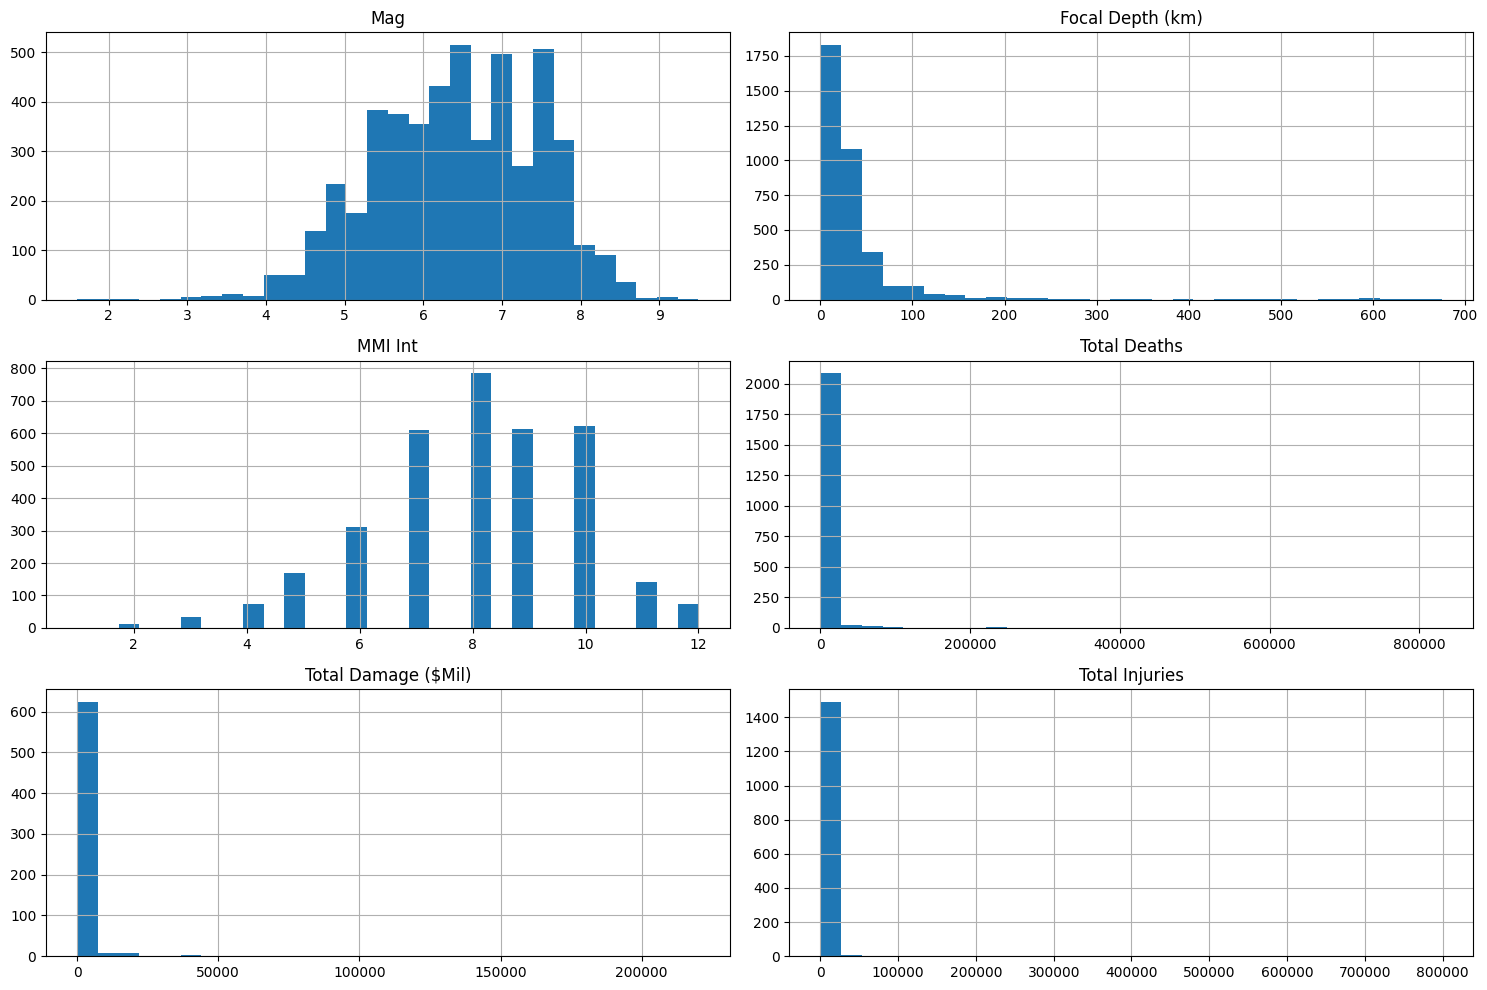

In [50]:
eq[columns].hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()

These boxplots compare the spread, median, and potential outliers of six numerical earthquake features.

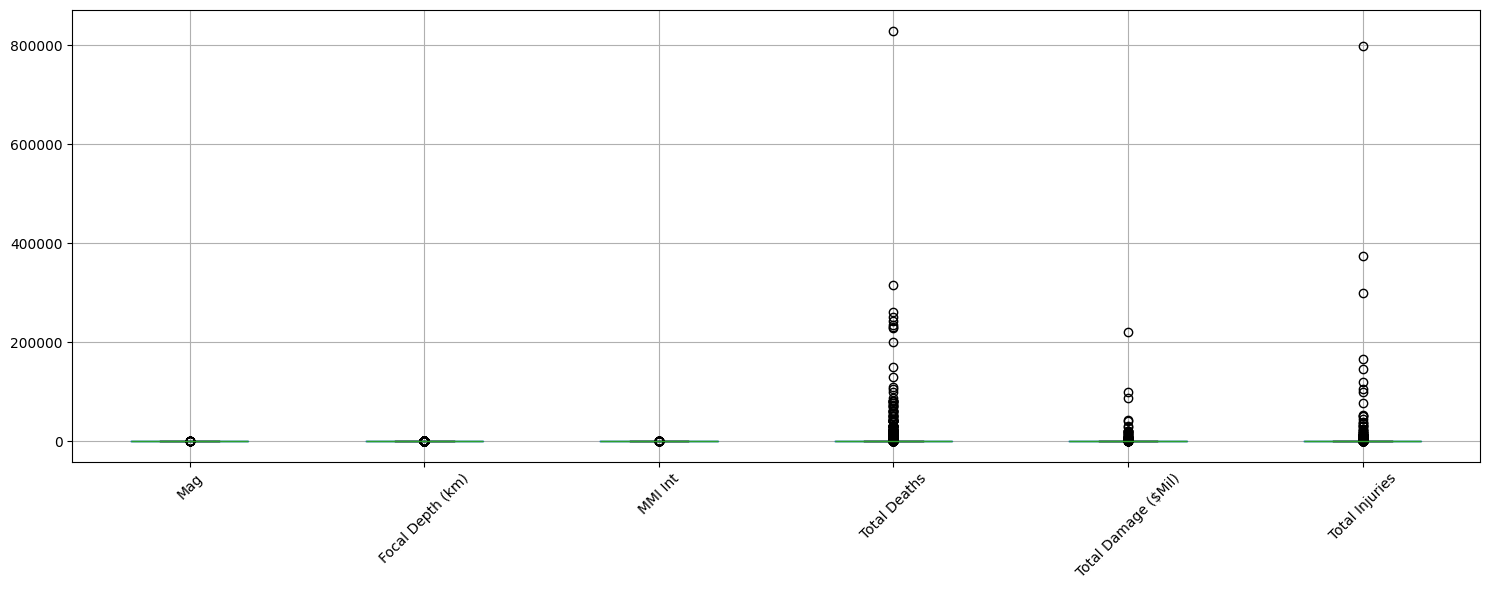

In [51]:
eq[columns].boxplot(figsize=(15, 6))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The scatter matrix compares earthquake magnitude, focal depth, and MMI intensity. Each scatterplot shows the relationship between two features, while the diagonal histograms display the distribution of each individual feature.

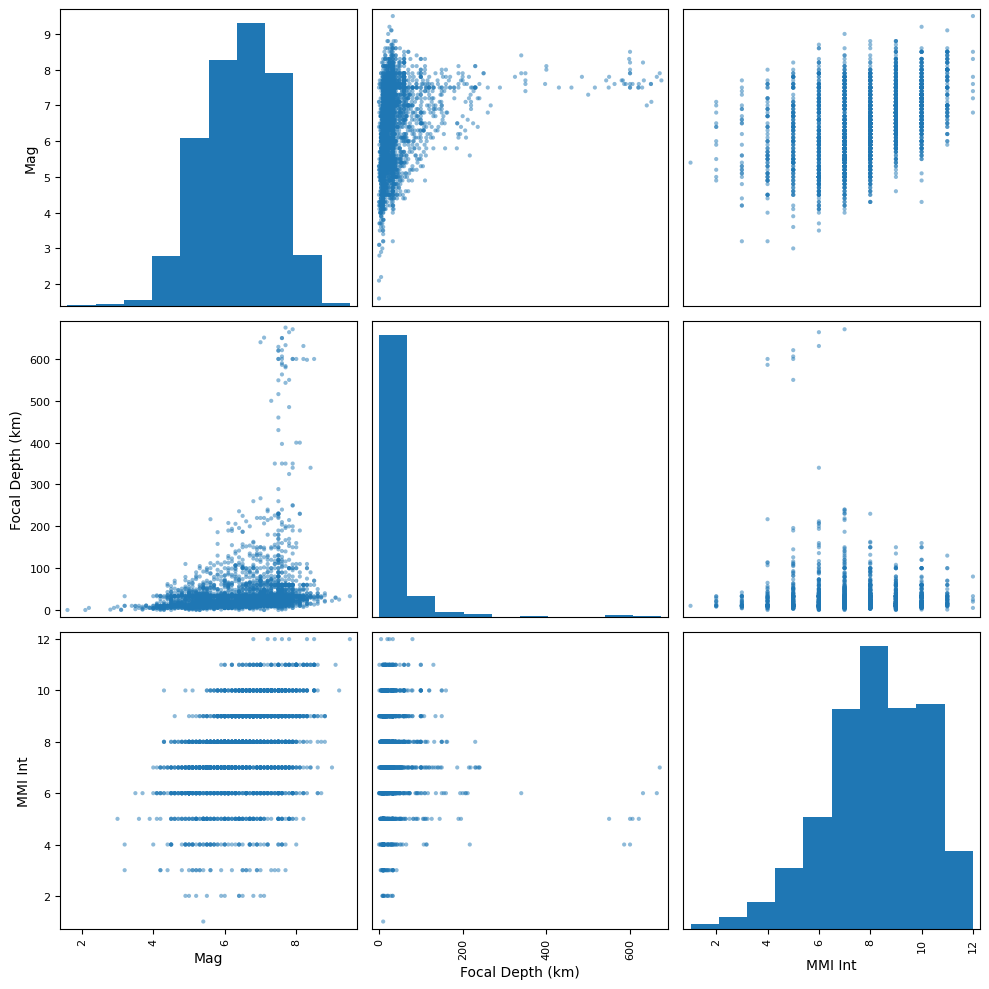

In [52]:
pd.plotting.scatter_matrix(
    eq[["Mag", "Focal Depth (km)", "MMI Int"]],
    figsize=(10, 10),
    diagonal="hist"
)
plt.tight_layout()
plt.show()